<a href="https://colab.research.google.com/github/ireniusliqfenermaward-maker/DataScience_hierarchial_clustering_6/blob/main/pertemuan2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. MENAMPILKAN DATA YANG ADA
      Nama  Usia     Gaji Jenis Kelamin
0      Ana    47  4700000     Perempuan
1     Budi    58  5500000     Laki-laki
2  Cecilia    49  5000000     Laki-laki
3     Dino    36  3500000     Laki-laki
4    Erlin     0  3000000     Perempuan
5    Fahmi    38  3500000     Laki-laki
6     Gina    48  4500000     Perempuan
7  Handoko    46        0     Laki-laki
8     Inas    41  4000000     Perempuan

2. MENAMPILKAN DATA KOSONG (MISSING VALUES)
Pemeriksaan data kosong (isnull):
Nama             0
Usia             0
Gaji             0
Jenis Kelamin    0
dtype: int64

Pemeriksaan nilai 0 yang tidak wajar (Missing Value Terselubung):
Jumlah nilai 0 pada Usia : 1
Jumlah nilai 0 pada Gaji : 1

3. PENANGANAN MISSING VALUES
Data setelah penanganan missing values (imputasi Median):
      Nama  Usia       Gaji Jenis Kelamin
0      Ana  47.0  4700000.0     Perempuan
1     Budi  58.0  5500000.0     Laki-laki
2  Cecilia  49.0  5000000.0     Laki-laki
3     Dino  36.0  3500

/tmp/ipykernel_1104/2053221295.py:32: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Usia'].fillna(df['Usia'].median(), inplace=True)
/tmp/ipykernel_1104/2053221295.py:33: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)'

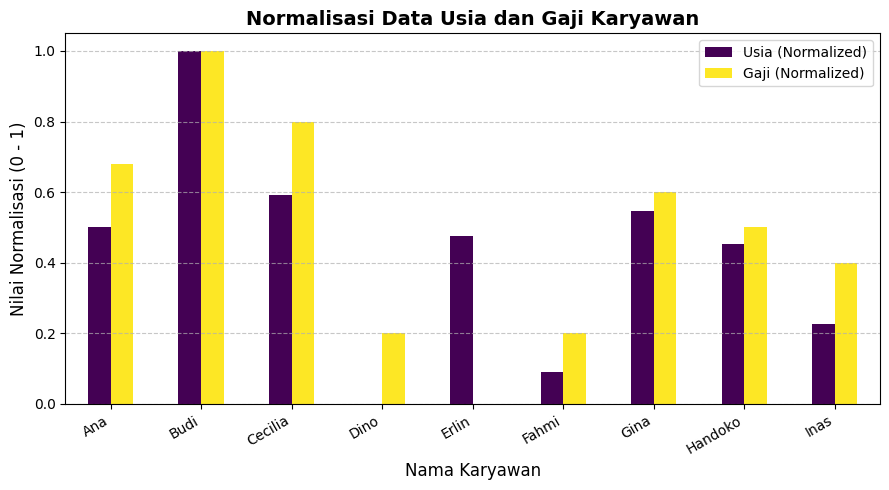

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

# 1. Membaca dataset DS_2.csv (menggunakan sep=';' karena pemisah kolomnya titik koma)
df = pd.read_csv('DS_2.csv', sep=';')

print("==========================================")
print("1. MENAMPILKAN DATA YANG ADA")
print("==========================================")
print(df)

print("\n==========================================")
print("2. MENAMPILKAN DATA KOSONG (MISSING VALUES)")
print("==========================================")
print("Pemeriksaan data kosong (isnull):")
print(df.isnull().sum())

print("\nPemeriksaan nilai 0 yang tidak wajar (Missing Value Terselubung):")
print(f"Jumlah nilai 0 pada Usia : {(df['Usia'] == 0).sum()}")
print(f"Jumlah nilai 0 pada Gaji : {(df['Gaji'] == 0).sum()}")

print("\n==========================================")
print("3. PENANGANAN MISSING VALUES")
print("==========================================")
# Mengubah nilai 0 menjadi NaN agar bisa ditangani
df['Usia'] = df['Usia'].replace(0, np.nan)
df['Gaji'] = df['Gaji'].replace(0, np.nan)

# Mengisi (imputasi) nilai yang kosong dengan nilai Median dari kolom masing-masing
df['Usia'].fillna(df['Usia'].median(), inplace=True)
df['Gaji'].fillna(df['Gaji'].median(), inplace=True)

print("Data setelah penanganan missing values (imputasi Median):")
print(df)

print("\n==========================================")
print("4. NORMALISASI DATA & VISUALISASI GRAFIK")
print("==========================================")
# Normalisasi data numerik ke rentang 0 sampai 1 menggunakan Min-Max Scaler
scaler = MinMaxScaler()
numeric_cols = ['Usia', 'Gaji']
df_normalized = df.copy()
df_normalized[numeric_cols] = scaler.fit_transform(df[numeric_cols])

print("Hasil Normalisasi Data:")
print(df_normalized[numeric_cols])

# Visualisasi data dalam bentuk grafik batang (bar chart)
df_normalized[numeric_cols].plot(kind='bar', figsize=(9, 5), colormap='viridis')
plt.title('Normalisasi Data Usia dan Gaji Karyawan', fontsize=14, fontweight='bold')
plt.xlabel('Nama Karyawan', fontsize=12)
plt.ylabel('Nilai Normalisasi (0 - 1)', fontsize=12)
plt.xticks(ticks=range(len(df)), labels=df['Nama'], rotation=30, ha='right')
plt.legend(['Usia (Normalized)', 'Gaji (Normalized)'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()